In [1]:
"""
Pangenome analysis #1

Amjad Khalaf
03/09/2026
"""

'\nPangenome analysis #1\n\nAmjad Khalaf\n03/09/2026\n'

In [1]:
# Setting up to filter things associated with TEs
# find which proteins are associated with TEs

TeProteins = []
import glob
interproscanFiles = glob.glob("//lustre/scratch126/tol/teams/lawniczak/projects/microsporidia/royalSoc/pangenomes/interproscan/*")
for file in interproscanFiles:
    with open(file) as f:
        for line in f:
            line = line.rstrip("\n")
            if "transposase" in line or "integrase" in line or "transposon" in line or "retrotransposon" in line:
                TeProteins.append(line.split("\t")[0])

print(TeProteins[:10]) ## sanity check

# for each orthogroup, count %  of the TE proteins that occur in them
OrthogroupScores = {} # key is orthogroup, value is % of TE annotations
from Bio import SeqIO
orthogroupFastas = glob.glob("/lustre/scratch126/tol/teams/lawniczak/projects/microsporidia/royalSoc/pangenomes/proteins/OrthoFinder/Results_Aug29/Orthogroup_Sequences/*")
for file in orthogroupFastas:
    orthogroup = file.split("/")[14].replace(".fa", "")
    teCount = 0
    records = list(SeqIO.parse(file, "fasta"))
    numberOfProteins = len(records)
    for record in records:
        if record.id in TeProteins:
            teCount = teCount + 1
    OrthogroupScores[orthogroup] = (teCount/numberOfProteins)*100


['AAOAPDOP_01135', 'AAOAPDOP_01298', 'AAOAPDOP_02256', 'CBJPFJEB_33556', 'CBJPFJEB_33029', 'CBJPFJEB_22189', 'CBJPFJEB_05138', 'CBJPFJEB_26246', 'CBJPFJEB_26246', 'CBJPFJEB_01820']


In [3]:
with open("/lustre/scratch126/tol/teams/lawniczak/projects/microsporidia/royalSoc/pangenomes/orthogroup_TE_scores.txt", "a+") as f:
    for orthogroup in OrthogroupScores.keys():
        outputLine = orthogroup + "\t" + str(OrthogroupScores[orthogroup])
        f.write(outputLine)
        f.write("\n")
f.close()

In [1]:
OrthogroupScores = {}
scoreFile = "/lustre/scratch126/tol/teams/lawniczak/projects/microsporidia/royalSoc/pangenomes/orthogroup_TE_scores.txt"
with open(scoreFile) as file:
    for line in file:
        line = line.rstrip("\n")
        fields = line.split("\t")
        orthogroup = fields[0]
        score = float(fields[1])
        OrthogroupScores[orthogroup] = score

774
252871


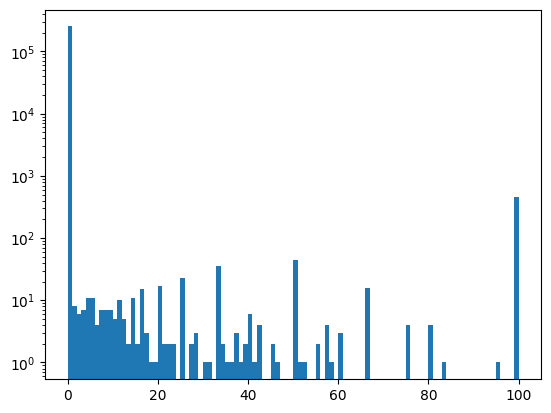

In [2]:
# plot score distribution
scores = []
for orthogroup in OrthogroupScores.keys():
    scores.append(OrthogroupScores[orthogroup])

import matplotlib.pyplot as plt
plt.hist(scores, bins = 100)
plt.yscale('log')

count = 0
for score in scores:
    if score >= 1:
      count = count + 1

print(count)
print(len(scores))

In [3]:
# Importing the orthofinder results

import pandas as pd
orthogroupsTSV = "/lustre/scratch126/tol/teams/lawniczak/projects/microsporidia/royalSoc/pangenomes/proteins/OrthoFinder/Results_Aug29/Orthogroups/Orthogroups.GeneCount.tsv"
df = pd.read_csv(orthogroupsTSV, sep='\t')

orthogroupDict = {} #Key is species, values is list of orthogroups
speciesList = []
with open(orthogroupsTSV) as file:
    for line in file:
        line = line.rstrip("\n")
        fields = line.split("\t")
        if fields[0] == "Orthogroup":
            speciesList = fields.copy()
        else:
            for i, field in enumerate(fields):
                if field.startswith("OG"):
                    orthogroup = field
                else:
                    if int(field) > 0:
                        # retrieve position of field in list to find out what species it is
                        species = speciesList[i]
                        if species in orthogroupDict.keys() and OrthogroupScores[orthogroup] < 1:
                            orthogroupDict[species].append(orthogroup)
                        else:
                            if OrthogroupScores[orthogroup] < 1:
                                orthogroupDict[species] = [orthogroup]

In [4]:
# Setting up comparisons between the established microsporidian orders
# one genome is included per species

from collections import defaultdict

Ovavesiculida_core = []
Ovavesiculida_genomes_sets = []
numOfOvavesiculidaGenomes = 0
Ovavesiculida_genome_names = []
Ovavesiculida_file = "/lustre/scratch126/tol/teams/lawniczak/projects/microsporidia/royalSoc/pangenomes/ovavesiculida_species_list.txt"
with open(Ovavesiculida_file) as f:
    for line in f:
        line = line.rstrip("\n")
        if line == "cjLepRept2":
            pass
        else:
            Ovavesiculida_genomes_sets.append(set(orthogroupDict[line]))
            numOfOvavesiculidaGenomes += 1
            Ovavesiculida_genome_names.append(line)

orthogroup_genome_counts = defaultdict(int)
for genome_set in Ovavesiculida_genomes_sets:
    for orthogroup in genome_set:
        orthogroup_genome_counts[orthogroup] += 1
for orthogroup, count in orthogroup_genome_counts.items():
    Ovavesiculida_core.append(orthogroup)


OrphanLineage_core = []
OrphanLineage_genomes_sets = []
numOfOrphanLineageGenomes = 0
OrphanLineage_genome_names = []
OrphanLineage_file = "/lustre/scratch126/tol/teams/lawniczak/projects/microsporidia/royalSoc/pangenomes/astathelohaniida_species_list.txt"
with open(OrphanLineage_file) as f:
    for line in f:
        line = line.rstrip("\n")
        OrphanLineage_genomes_sets.append(set(orthogroupDict[line]))
        numOfOrphanLineageGenomes += 1
        OrphanLineage_genome_names.append(line)

orthogroup_genome_counts = defaultdict(int)
for genome_set in OrphanLineage_genomes_sets:
    for orthogroup in genome_set:
        orthogroup_genome_counts[orthogroup] += 1
for orthogroup, count in orthogroup_genome_counts.items():
    OrphanLineage_core.append(orthogroup)

Amblyosporida_core = []
Amblyosporida_genomes_sets = []
numOfAmblyosporidaGenomes = 0
Amblyosporida_genome_names = []
Amblyosporida_file = "/lustre/scratch126/tol/teams/lawniczak/projects/microsporidia/royalSoc/pangenomes/amblyosporida_species_list.txt"
with open(Amblyosporida_file) as f:
    for line in f:
        line = line.rstrip("\n")
        if line == "idAnoSqua2_b" or line == "ilAceEphe1_GCA_986199865.1" or line =="idMegDoli1_GCA_985805875.1" or line == "idLucSpea1_GCA_985809255.1":
            pass
        else:
            Amblyosporida_genomes_sets.append(set(orthogroupDict[line]))
            numOfAmblyosporidaGenomes += 1
            Amblyosporida_genome_names.append(line)

orthogroup_genome_counts = defaultdict(int)
for genome_set in Amblyosporida_genomes_sets:
    for orthogroup in genome_set:
        orthogroup_genome_counts[orthogroup] += 1
for orthogroup, count in orthogroup_genome_counts.items():
    Amblyosporida_core.append(orthogroup)

Glugeida_core = []
Glugeida_genomes_sets = []
numOfGlugeidaGenomes = 0
Glugeida_genome_names = []
Glugeida_file = "/lustre/scratch126/tol/teams/lawniczak/projects/microsporidia/royalSoc/pangenomes/glugeida_species_list.txt"
with open(Glugeida_file) as f:
    for line in f:
        line = line.rstrip("\n")
        if line == "Dictyocoela_roeselum_GCA_016255985.1" or line == "Pseudoloma_neurophilia_GCA_001432165.1" or line == "Cucumispora_dikerogammari_GCA_014805705.1":
            pass
        else:
            Glugeida_genomes_sets.append(set(orthogroupDict[line]))
            numOfGlugeidaGenomes += 1
            Glugeida_genome_names.append(line)

orthogroup_genome_counts = defaultdict(int)
for genome_set in Glugeida_genomes_sets:
    for orthogroup in genome_set:
        orthogroup_genome_counts[orthogroup] += 1
for orthogroup, count in orthogroup_genome_counts.items():
    Glugeida_core.append(orthogroup)

Neopereziida_core = []
Neopereziida_genomes_sets = []
numOfNeopereziidaGenomes = 0
Neopereziida_genome_names = []
Neopereziida_file = "/lustre/scratch126/tol/teams/lawniczak/projects/microsporidia/royalSoc/pangenomes/neopereziida_species_list.txt"
with open(Neopereziida_file) as f:
    for line in f:
        line = line.rstrip("\n")
        if line == "ieEphVulg1_GCA_985806015.1" or line == "idTipConf1_GCA_985805865.1":
            pass
        else:
            Neopereziida_genomes_sets.append(set(orthogroupDict[line]))
            numOfNeopereziidaGenomes += 1
            Neopereziida_genome_names.append(line)

orthogroup_genome_counts = defaultdict(int)
for genome_set in Neopereziida_genomes_sets:
    for orthogroup in genome_set:
        orthogroup_genome_counts[orthogroup] += 1
for orthogroup, count in orthogroup_genome_counts.items():
    Neopereziida_core.append(orthogroup)


Nosematida_core = []
Nosematida_genomes_sets = []
numOfNosematidaGenomes = 0
Nosematida_genome_names = []
Nosematida_file = "/lustre/scratch126/tol/teams/lawniczak/projects/microsporidia/royalSoc/pangenomes/nosematida_species_list.txt"
with open(Nosematida_file) as f:
    for line in f:
        line = line.rstrip("\n")
        if line == "ilMytImpu1_GCA_986195055.1" or line == "ihCicViri2_GCA_985805755.1" or line == "iyVulBima1_GCA_985801995.1" or line == "Nosema_muscidifuracis_GCA_028335825.1" or line == "iyGorLati1" or line == "ilBlaLact1_GCA_986194925.1" or line == "icChrPopu2" or line == "ilEreLige1_GCA_986264945.1" or line == "ilNocJanh1_GCA_986264975.1" or line == "iyForRufa2_GCA_985801395.1" or line == "Nosema_rusticus_GCA_046563365.1" or line == "iyAmbProt1_GCA_986191025.1" or line == "iySphCras2_GCA_985800635.1" or line == "iyNetVirg2_GCA_985803815.1" or line == "iyChoSubc1_GCA_986194725.1" or line == "ilOchDupl1_GCA_986194575.1":
            pass
        else:
            Nosematida_genomes_sets.append(set(orthogroupDict[line]))
            numOfNosematidaGenomes += 1
            Nosematida_genome_names.append(line)

orthogroup_genome_counts = defaultdict(int)
for genome_set in Nosematida_genomes_sets:
    for orthogroup in genome_set:
        orthogroup_genome_counts[orthogroup] += 1
for orthogroup, count in orthogroup_genome_counts.items():
    Nosematida_core.append(orthogroup)

Enterocytozoonida_core = []
Enterocytozoonida_genomes_sets = []
numOfEnterocytozoonidaGenomes = 0
Enterocytozoonida_genome_names = []
Enterocytozoonida_file = "/lustre/scratch126/tol/teams/lawniczak/projects/microsporidia/royalSoc/pangenomes/enterocytozoonida_species_list.txt"
with open(Enterocytozoonida_file) as f:
    for line in f:
        line = line.rstrip("\n")
        if line == "icHarAnxi1" or line == "Agmasoma_sp_GCA_029232285.1" or line == "Hepatospora_eriocheir_GCA_002087885.1" or line == "Enterocytozoon_hepatopenaei_GCA_026692725.1" or line == "Enterospora_canceri_GCA_002087915.1" or line == "Enterocytozoon_bieneusi_GCA_000209485.1" or line == "iqTelOcea3_a" or line == "iqTelOcea30" or line == "icAcuMacu1" or line == "ieEcdTorr1" or line == "cbUloPhyl1" or line == "idNeuQuad1_GCA_985805835.1" or line == "icBraCrep1" or line == "idAnoSqua2_a" or line == "idHydMili2_a" or line == "Alternosema_astaquatica_GCA_030386735.1":
            pass
        else:
            Enterocytozoonida_genomes_sets.append(set(orthogroupDict[line]))
            numOfEnterocytozoonidaGenomes += 1
            Enterocytozoonida_genome_names.append(line)

orthogroup_genome_counts = defaultdict(int)
for genome_set in Enterocytozoonida_genomes_sets:
    for orthogroup in genome_set:
        orthogroup_genome_counts[orthogroup] += 1
for orthogroup, count in orthogroup_genome_counts.items():
    Enterocytozoonida_core.append(orthogroup)


Mitosporidium = orthogroupDict["Mitosporidium_daphniae_GCA_052576055.1"]
qlDicSaun7 = orthogroupDict["qlDicSaun7"]
Mitosporidia_core = list(set(Mitosporidium).union(set(qlDicSaun7)))

Metchnikovella = orthogroupDict["Metchnikovella_incurvata_GCA_003600395.1"]
Amphiamblys = orthogroupDict["Amphiamblys_sp._WSBS2006_GCA_001875675.1"]
Metchnikovellida_core = list(set(Amphiamblys).union(set(Metchnikovella)))

Mitosporidia_core = list(set(Mitosporidia_core))
Metchnikovellida_core = list(set(Metchnikovellida_core))
Ovavesiculida_core = list(set(Ovavesiculida_core))
Neopereziida_core = list(set(Neopereziida_core))
Nosematida_core = list(set(Nosematida_core))
Enterocytozoonida_core = list(set(Enterocytozoonida_core))
Glugeida_core = list(set(Glugeida_core))
Amblyosporida_core = list(set(Amblyosporida_core))
OrphanLineage_core = list(set(OrphanLineage_core))


/software/treeoflife/conda/users/envs/team222/ak37/toytree/lib/python3.11/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/software/treeoflife/conda/users/envs/team222/ak37/toytree/lib/python3.11/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation

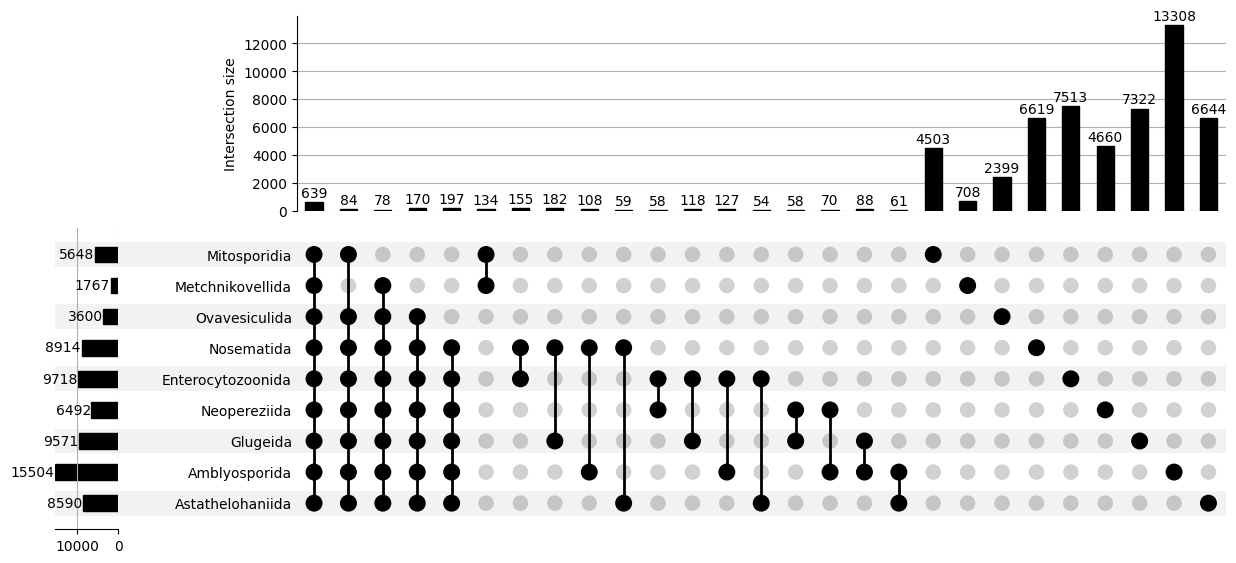

In [43]:
# drawing upset plot
# panel A

import matplotlib.pyplot as plt
from upsetplot import UpSet, from_contents

plt.rcParams['svg.fonttype'] = 'none'

data_lists = {
    'Mitosporidia': Mitosporidia_core,
    'Metchnikovellida': Metchnikovellida_core,
    'Ovavesiculida': Ovavesiculida_core,
    'Nosematida': Nosematida_core,
    'Enterocytozoonida': Enterocytozoonida_core,
    'Neopereziida': Neopereziida_core,
    'Glugeida': Glugeida_core,
    'Amblyosporida': Amblyosporida_core,
    'Astathelohaniida': OrphanLineage_core
}

upset_data = from_contents(data_lists)
upset_plot = UpSet(upset_data, show_counts=True, sort_categories_by='-input', min_subset_size=50, sort_by='-degree')
upset_plot.plot()
plt.savefig("/lustre/scratch126/tol/teams/lawniczak/projects/microsporidia/royalSoc/pangenomes/upsetPlot/upsetPlot_A.svg")
plt.show()

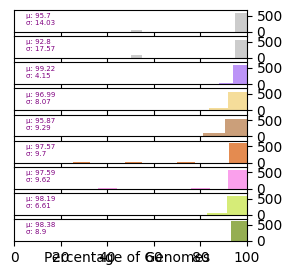

In [ ]:
### intersection 1
# panel B

import matplotlib.pyplot as plt
from upsetplot import UpSet, from_contents

plt.rcParams['svg.fonttype'] = 'none'
import statistics

colors = ["#ccccccff", "#ccccccff", "#bc94f7ff", "#f5dd9aff", "#cb9f7aff", "#e48b50ff", "#faa0ecff", "#d6ec78ff", "#95ae52ff"]

u = set.intersection(set(Mitosporidia_core), set(Metchnikovellida_core), set(Ovavesiculida_core), set(Nosematida_core), set(Enterocytozoonida_core), set(Neopereziida_core), set(Glugeida_core), set(Amblyosporida_core), set(OrphanLineage_core))

fig, axs = plt.subplots(9, 1, sharex=True)
fig.set_figheight(3)
fig.set_figwidth(3)
fig.text(0.5, 0.04, 'Percentage of Genomes', ha='center')

orderNames = ["Mitosporidia", "Metchnikovellida", "Ovavesiculida", "Nosematida", "Enterocytozoonida", "Neopereziida", "Glugeida", "Amblyosporida", "Orphan Lineage"]
orderGenomeSets = [[qlDicSaun7, Mitosporidium], [Amphiamblys, Metchnikovella], Ovavesiculida_genomes_sets, Nosematida_genomes_sets, Enterocytozoonida_genomes_sets, Neopereziida_genomes_sets, Glugeida_genomes_sets, Amblyosporida_genomes_sets, OrphanLineage_genomes_sets]
distributions = []
for index, order in enumerate(orderGenomeSets):
    counts = []
    for gene in u:
        count = 0
        for genomeSet in order:
            if gene in genomeSet:
                count = count + 1

        counts.append(((count)/len(order))*100)
    distributions.append(counts)
    mean = round(statistics.mean(counts), 2)
    sd = round(statistics.stdev(counts),2)

    axs[index].hist(counts, bins=10, color=colors[index])
    axs[index].set_ylim(0, 670)
    text = "µ: " + str(mean) + " \nσ: " + str(sd)
    axs[index].text(5, 200, text, size=5, color='purple')
    axs[index].yaxis.tick_right()
    axs[index].set_xlim(0,100)


plt.savefig("/lustre/scratch126/tol/teams/lawniczak/projects/microsporidia/royalSoc/pangenomes/upsetPlot/upsetPlot_B.svg")
plt.show()

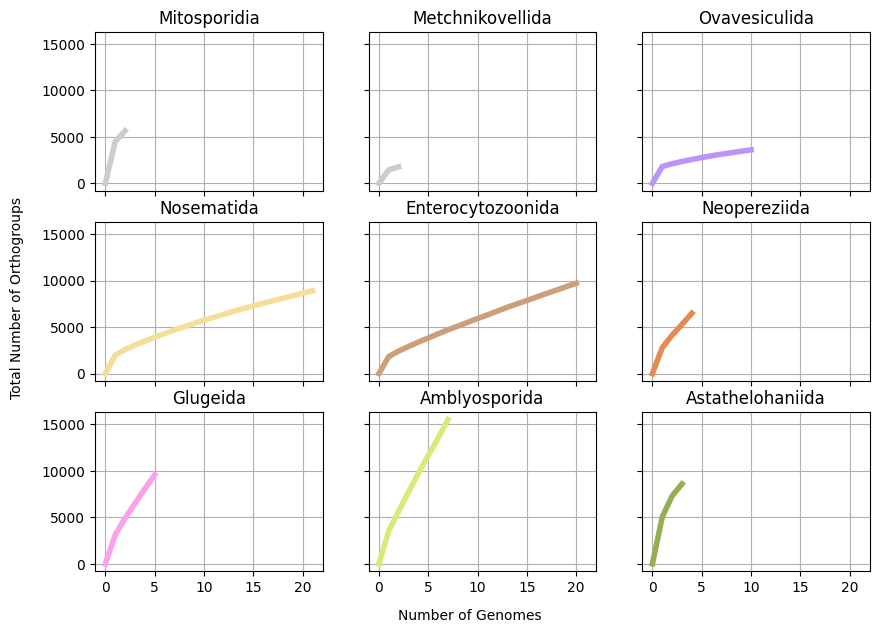

In [45]:
# drawing rarefaction curves
# Panel C

import random
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['svg.fonttype'] = 'none'


ordersGenomeSets = [[set(Mitosporidium), set(qlDicSaun7)], [set(Metchnikovella), set(Amphiamblys)], Ovavesiculida_genomes_sets, Nosematida_genomes_sets, Enterocytozoonida_genomes_sets, Neopereziida_genomes_sets, Glugeida_genomes_sets, Amblyosporida_genomes_sets, OrphanLineage_genomes_sets]
ordersCoreGeneLists = [Mitosporidia_core, Metchnikovellida_core, Ovavesiculida_core, Nosematida_core, Enterocytozoonida_core, Neopereziida_core, Glugeida_core, Amblyosporida_core, OrphanLineage_core]
orderNames = ["Mitosporidia", "Metchnikovellida", "Ovavesiculida", "Nosematida", "Enterocytozoonida", "Neopereziida", "Glugeida", "Amblyosporida", "Astathelohaniida"]

position = [(0,0), (0,1), (0,2), 
            (1,0),  (1,1), (1,2), 
            (2,0), (2,1), (2,2)]

fig, axs = plt.subplots(3, 3, sharex=True, sharey=True)
fig.set_figheight(7)
fig.set_figwidth(10)
fig.text(0.5, 0.04, 'Number of Genomes', ha='center')
fig.text(0.04, 0.5, 'Total Number of Orthogroups', va='center', rotation='vertical')

for index, (orderGenomeSet, orderName) in enumerate(zip(ordersGenomeSets, ordersCoreGeneLists)):
    num_genomes = len(orderGenomeSet)
    x = list(range(num_genomes + 1))
    
    all_pan_curves = []
    
    for _ in range(1, 1000):
        current_order = list(orderGenomeSet)
        random.shuffle(current_order)
        
        pan_curve = [0]
        
        genomes_sampled_so_far = []
        for count, genome_set in enumerate(current_order, start=1):
            genomes_sampled_so_far.append(genome_set)
            
            pan_genes = set().union(*genomes_sampled_so_far)
            pan_curve.append(len(pan_genes))
            
            
        all_pan_curves.append(pan_curve)
        
    avg_pan = np.mean(all_pan_curves, axis=0)
    
    pos = position[index]
    axs[pos].plot(x, avg_pan, color=colors[index], linewidth=4)
    axs[pos].set_title(orderNames[index])
    axs[pos].grid(True)

plt.savefig("/lustre/scratch126/tol/teams/lawniczak/projects/microsporidia/royalSoc/pangenomes/upsetPlot/upsetPlot_C.svg")

/software/treeoflife/conda/users/envs/team222/ak37/toytree/lib/python3.11/site-packages/matplotlib/scale.py:253: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


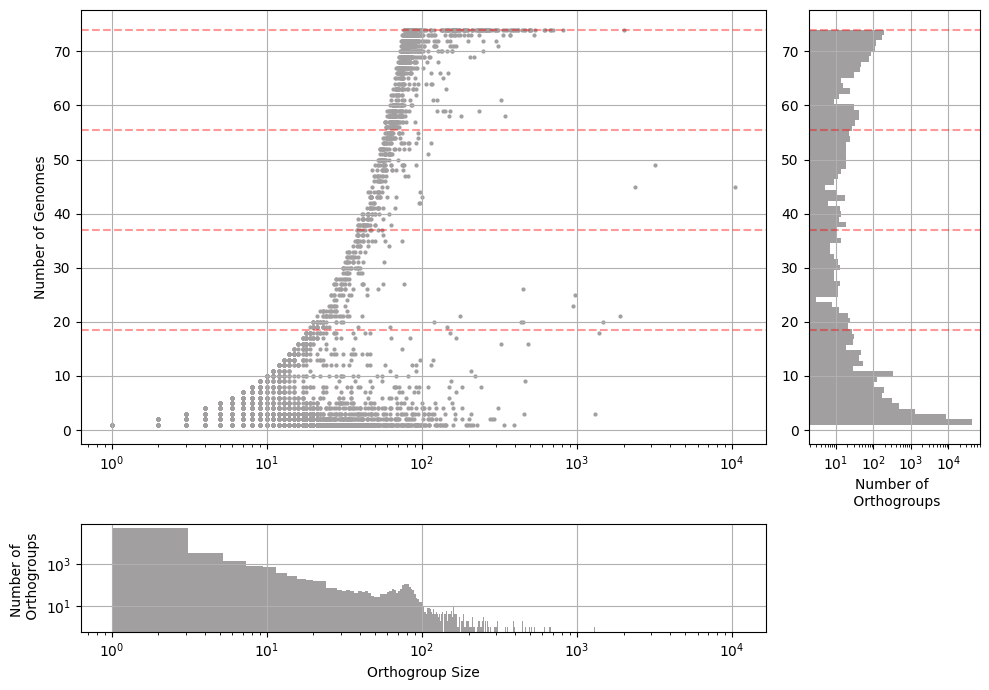

In [46]:
finalGenomes = Ovavesiculida_genome_names + Nosematida_genome_names + Enterocytozoonida_genome_names + Neopereziida_genome_names + Glugeida_genome_names + Amblyosporida_genome_names + OrphanLineage_genome_names
finalGenomes.append("Mitosporidium_daphniae_GCA_052576055.1")
finalGenomes.append("qlDicSaun7")
finalGenomes.append("Metchnikovella_incurvata_GCA_003600395.1")
finalGenomes.append("Amphiamblys_sp._WSBS2006_GCA_001875675.1")

totalGenomeNum = len(finalGenomes)


import pandas as pd
df = pd.read_csv(orthogroupsTSV, sep='\t')

orthogroupDict = {} #Key is orthogroup, value is list of: [total cluster size, number of species in cluster]
speciesList = []

with open(orthogroupsTSV) as file:
    for line in file:
        line = line.rstrip("\n")
        fields = line.split("\t")
        if fields[0] == "Orthogroup":
            speciesList = fields[1:-1]
        else:
            numberOfSpecies = 0
            clusterSize = 0
            orthogroup = fields[0]
            if OrthogroupScores[orthogroup] < 1:
                for i, field in enumerate(fields[1:-1]):
                        if speciesList[i] in finalGenomes:
                            if int(field) > 0:
                                # retrieve position of field in list to find out what species it is
                                numberOfSpecies = numberOfSpecies + 1
                                clusterSize = clusterSize + int(field)
                orthogroupDict[orthogroup] = [clusterSize, numberOfSpecies]


# exclude 0s
clusterSize = []
numberOfSpecies = []
for orthogroup in orthogroupDict.keys():
    if int(orthogroupDict[orthogroup][0]) != 0:
        clusterSize.append(int(orthogroupDict[orthogroup][0]))
        numberOfSpecies.append(int(orthogroupDict[orthogroup][1]))


plt.rcParams['svg.fonttype'] = 'none'
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(nrows=2, ncols=2, gridspec_kw={'width_ratios': [4, 1], 'height_ratios': [4, 1]})
fig.set_figheight(7)
fig.set_figwidth(10)


ax1.sharex(ax3)
ax1.sharey(ax2) 

ax1.scatter(clusterSize, numberOfSpecies, s=4, c="#A19F9FFF", rasterized=True)
ax1.set_ylabel("Number of Genomes")
ax1.set_xscale('log') 
ax1.grid(axis="x")
ax1.grid(axis="y")
ax1.axhline(y=totalGenomeNum, xmin=0, xmax=50000, linestyle='dashed', color='red', alpha=0.4) #100%
ax1.axhline(y=totalGenomeNum*0.75, xmin=0, xmax=50000, linestyle='dashed', color='red', alpha=0.4) #75%
ax1.axhline(y=totalGenomeNum*0.5, xmin=0, xmax=50000, linestyle='dashed', color='red', alpha=0.4) #50%
ax1.axhline(y=totalGenomeNum*0.25, xmin=0, xmax=50000, linestyle='dashed', color='red', alpha=0.4) #25%



ax2.hist(numberOfSpecies, bins=totalGenomeNum, orientation = "horizontal", color="#A19F9FFF", rasterized=True)
ax2.set_xscale('log') 
ax2.set_xlabel("Number of \n Orthogroups")
ax2.grid(axis="x")
ax2.grid(axis="y")
ax2.axhline(y=totalGenomeNum, xmin=0, xmax=50000, linestyle='dashed', color='red', alpha=0.4) #100%
ax2.axhline(y=totalGenomeNum*0.75, xmin=0, xmax=50000, linestyle='dashed', color='red', alpha=0.4) #75%
ax2.axhline(y=totalGenomeNum*0.5, xmin=0, xmax=50000, linestyle='dashed', color='red', alpha=0.4) #50%
ax2.axhline(y=totalGenomeNum*0.25, xmin=0, xmax=50000, linestyle='dashed', color='red', alpha=0.4) #25%


ax3.hist(clusterSize, bins=5000, color="#A19F9FFF", rasterized=True)
ax3.set_yscale('log') 
ax3.set_xlabel("Orthogroup Size")
ax3.set_ylabel("Number of \n Orthogroups")
ax3.grid(axis="x")
ax3.grid(axis="y")


ax4.axis('off')
plt.tight_layout()
plt.savefig("/lustre/scratch126/tol/teams/lawniczak/projects/microsporidia/royalSoc/pangenomes/upsetPlot/upsetPlot_D.svg")
plt.show()

In [ ]:
## genuinely 100% present in everything !
all_genome_sets = []
for entry in finalGenomes:
    all_genome_sets.append(set(orthogroupDict[entry]))


len(list(all_genome_sets[0].intersection(*all_genome_sets[1:])))

191

In [12]:
# genes in both mito and metchnikovellida, but absent from core microsporidia

u = set.union(set(Ovavesiculida_core), set(Nosematida_core), set(Enterocytozoonida_core), set(Neopereziida_core), set(Glugeida_core), set(Amblyosporida_core), set(OrphanLineage_core))

print(len(set(Mitosporidia_core).intersection(set(Metchnikovellida_core)) - u))

m = (set(Mitosporidia_core).intersection(set(Metchnikovellida_core)) - u)

134


In [13]:

from pathlib import Path

GeneDict = {}
with open("/lustre/scratch126/tol/teams/lawniczak/projects/microsporidia/royalSoc/pangenomes/proteins/OrthoFinder/Results_Aug29/Orthogroups/Orthogroups.tsv") as file:
    GeneDict = {}

    for line in file:
        fields = line.rstrip("\n").split("\t")

        orthogroup = fields[0]
        if orthogroup in m:
            genes = [gene for gene in fields[1:] if gene]
            GeneDict[orthogroup] = genes

for orthogroup, genes in GeneDict.items():
    print(orthogroup, genes)


OG0002456 ['PPMAJOIP_00028, PPMAJOIP_00109, PPMAJOIP_00123, PPMAJOIP_00183, PPMAJOIP_00272, PPMAJOIP_00292, PPMAJOIP_00389, PPMAJOIP_00402, PPMAJOIP_00403, PPMAJOIP_00464, PPMAJOIP_00718, PPMAJOIP_01045, PPMAJOIP_01060, PPMAJOIP_01091, PPMAJOIP_01109, PPMAJOIP_01148, PPMAJOIP_01257, PPMAJOIP_01334, PPMAJOIP_01474, PPMAJOIP_01695, PPMAJOIP_01700, PPMAJOIP_01728, PPMAJOIP_01795, PPMAJOIP_01826, PPMAJOIP_01918, PPMAJOIP_01979, PPMAJOIP_02143, PPMAJOIP_02214, PPMAJOIP_02286, PPMAJOIP_02509, PPMAJOIP_02561, PPMAJOIP_02588, PPMAJOIP_02813, PPMAJOIP_02814, PPMAJOIP_03373, PPMAJOIP_03595, PPMAJOIP_04297, PPMAJOIP_04566, PPMAJOIP_04686, PPMAJOIP_05007, PPMAJOIP_05050, PPMAJOIP_05051, PPMAJOIP_05426', 'NDDJBOCF_02135, NDDJBOCF_03230, NDDJBOCF_04406', 'LIHKLAIP_00539', 'EHNNOHOK_00291']
OG0005649 ['PPMAJOIP_01872', 'NDDJBOCF_03768', 'LIHKLAIP_01608, LIHKLAIP_04954, LIHKLAIP_05068', 'EHNNOHOK_00756, EHNNOHOK_05740', 'PBNMAHBP_00432, PBNMAHBP_00433, PBNMAHBP_03239, PBNMAHBP_03240, PBNMAHBP_03544, P

In [14]:
directory = Path("/lustre/scratch126/tol/teams/lawniczak/projects/microsporidia/royalSoc/pangenomes/interproscan")

gene_to_orthogroup = {}

for orthogroup in m:
    for gene in GeneDict[orthogroup]:
        gene_to_orthogroup[gene] = orthogroup

for file in directory.glob("*.interproscan"):
    with open(file) as f:
        for line in f:
            fields = line.rstrip("\n").split("\t")
            gene = fields[0]

            if gene in gene_to_orthogroup:
                orthogroup = gene_to_orthogroup[gene]
                updatedLine = ""
                for field in fields:
                    if "Reactome" in field:
                        pass
                    else:
                        updatedLine = updatedLine + "\t" + field
                print(orthogroup, file.name, updatedLine)

OG0005885 cjLepRept2.interproscan 	EIPFCCEI_02677	1bfa3e8a5397329fbe252175b14f9c64	440	Pfam	PF03721	UDP-glucose/GDP-mannose dehydrogenase family, NAD binding domain	2	179	6.8E-59	T	27-08-2026	IPR001732	UDP-glucose/GDP-mannose dehydrogenase, N-terminal	GO:0016616|GO:0051287
OG0005885 cjLepRept2.interproscan 	EIPFCCEI_02677	1bfa3e8a5397329fbe252175b14f9c64	440	SMART	SM00984	UDPG_MGDP_dh_C_a_2_a	313	414	1.8E-44	T	27-08-2026	IPR014027	UDP-glucose/GDP-mannose dehydrogenase, C-terminal	GO:0016616|GO:0051287
OG0005885 cjLepRept2.interproscan 	EIPFCCEI_02677	1bfa3e8a5397329fbe252175b14f9c64	440	TIGRFAM	TIGR03026	NDP-sugDHase: nucleotide sugar dehydrogenase	2	410	3.1E-130	T	27-08-2026	IPR017476	UDP-glucose/GDP-mannose dehydrogenase	GO:0016616
OG0005885 cjLepRept2.interproscan 	EIPFCCEI_02677	1bfa3e8a5397329fbe252175b14f9c64	440	SUPERFAMILY	SSF48179	6-phosphogluconate dehydrogenase C-terminal domain-like	197	290	7.65E-32	T	27-08-2026	IPR008927	6-phosphogluconate dehydrogenase-like, C-terminal do